# 03 - K-NN sobre todas las parejas de variables del dataset Titanic

**Objetivo:** aplicar K-NN a todas las parejas de variables generadas en la etapa de *Feature Engineering* y graficar las regiones de decisión que produce cada pareja.

Pasos:
1. Cargar el dataset Titanic.
2. Feature Engineering.
3. Para cada pareja de variables: entrenar K-NN, medir su exactitud y graficar las regiones de decisión.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

## 1. Carga de datos

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Feature Engineering

Variables que se generan o transforman:

| Variable | Descripción |
|---|---|
| `Pclass` | Clase del boleto (1, 2, 3) |
| `Sex` | 0 = hombre, 1 = mujer |
| `Age` | Edad; los faltantes se imputan con la mediana según el título |
| `Fare` | Tarifa en escala logarítmica, `log(1 + Fare)` |
| `Embarked` | Puerto de embarque codificado (S = 0, C = 1, Q = 2) |
| `FamilySize` | `SibSp + Parch + 1` |
| `IsAlone` | 1 si viaja solo, 0 si no |
| `Title` | Título extraído del nombre (Mr, Miss, Mrs, Master, Raro) codificado |

In [3]:
data = df.copy()

# Título a partir del nombre
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
data["Title"] = data["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
data.loc[~data["Title"].isin(["Mr", "Miss", "Mrs", "Master"]), "Title"] = "Raro"

# Edad: mediana por título
data["Age"] = data["Age"].fillna(data.groupby("Title")["Age"].transform("median"))

# Sexo y puerto de embarque
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
data["Embarked"] = data["Embarked"].map({"S": 0, "C": 1, "Q": 2})

# Familia
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Tarifa en escala log
data["Fare"] = np.log1p(data["Fare"])

# Título codificado
data["Title"] = data["Title"].map({"Mr": 0, "Miss": 1, "Mrs": 2, "Master": 3, "Raro": 4})

features = ["Pclass", "Sex", "Age", "Fare", "Embarked", "FamilySize", "IsAlone", "Title"]
X = data[features]
y = data["Survived"]

print("Valores faltantes:", X.isna().sum().sum())
X.head()

Valores faltantes: 0


,Pclass,Sex,Age,Fare,Embarked,FamilySize,IsAlone,Title
0,3,0,22.0,2.110213,0,2,0,0
1,1,1,38.0,4.280593,1,2,0,2
2,3,1,26.0,2.188856,0,1,1,1
3,1,1,35.0,3.990834,0,2,0,2
4,3,0,35.0,2.202765,0,1,1,0


## 3. K-NN en todas las parejas de variables

Con 8 variables hay C(8, 2) = 28 parejas. Para cada una:
- Se separan los datos en entrenamiento (70 %) y prueba (30 %) con la misma semilla.
- Se escalan las dos variables con `StandardScaler`, porque K-NN usa distancias y las variables tienen escalas muy distintas (por ejemplo `Age` contra `Sex`).
- Se entrena K-NN con k = 5 y se mide la exactitud en prueba.

In [4]:
K = 5
pairs = list(itertools.combinations(features, 2))
print("Número de parejas:", len(pairs))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

results = []
models = {}
for f1, f2 in pairs:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K))
    model.fit(X_train[[f1, f2]], y_train)
    acc = model.score(X_test[[f1, f2]], y_test)
    models[(f1, f2)] = model
    results.append({"Variable 1": f1, "Variable 2": f2, "Exactitud": round(acc, 3)})

results_df = pd.DataFrame(results).sort_values("Exactitud", ascending=False).reset_index(drop=True)
results_df

Número de parejas: 28


,Variable 1,Variable 2,Exactitud
0,FamilySize,Title,0.813
1,Sex,FamilySize,0.802
2,Pclass,Sex,0.799
3,Sex,Title,0.784
4,Embarked,Title,0.780
5,Sex,Embarked,0.776
6,Sex,IsAlone,0.776
7,Sex,Age,0.772
8,Fare,Title,0.765
9,Pclass,Title,0.765


## 4. Regiones de decisión

Cada gráfica muestra una pareja de variables. El color de fondo es la clase que predice K-NN en esa zona (**rojo = no sobrevivió**, **azul = sobrevivió**) y los puntos son los pasajeros de entrenamiento. A los puntos se les agrega un pequeño ruido solo al dibujarlos, para que no se encimen en las variables discretas como `Sex` o `Pclass`.

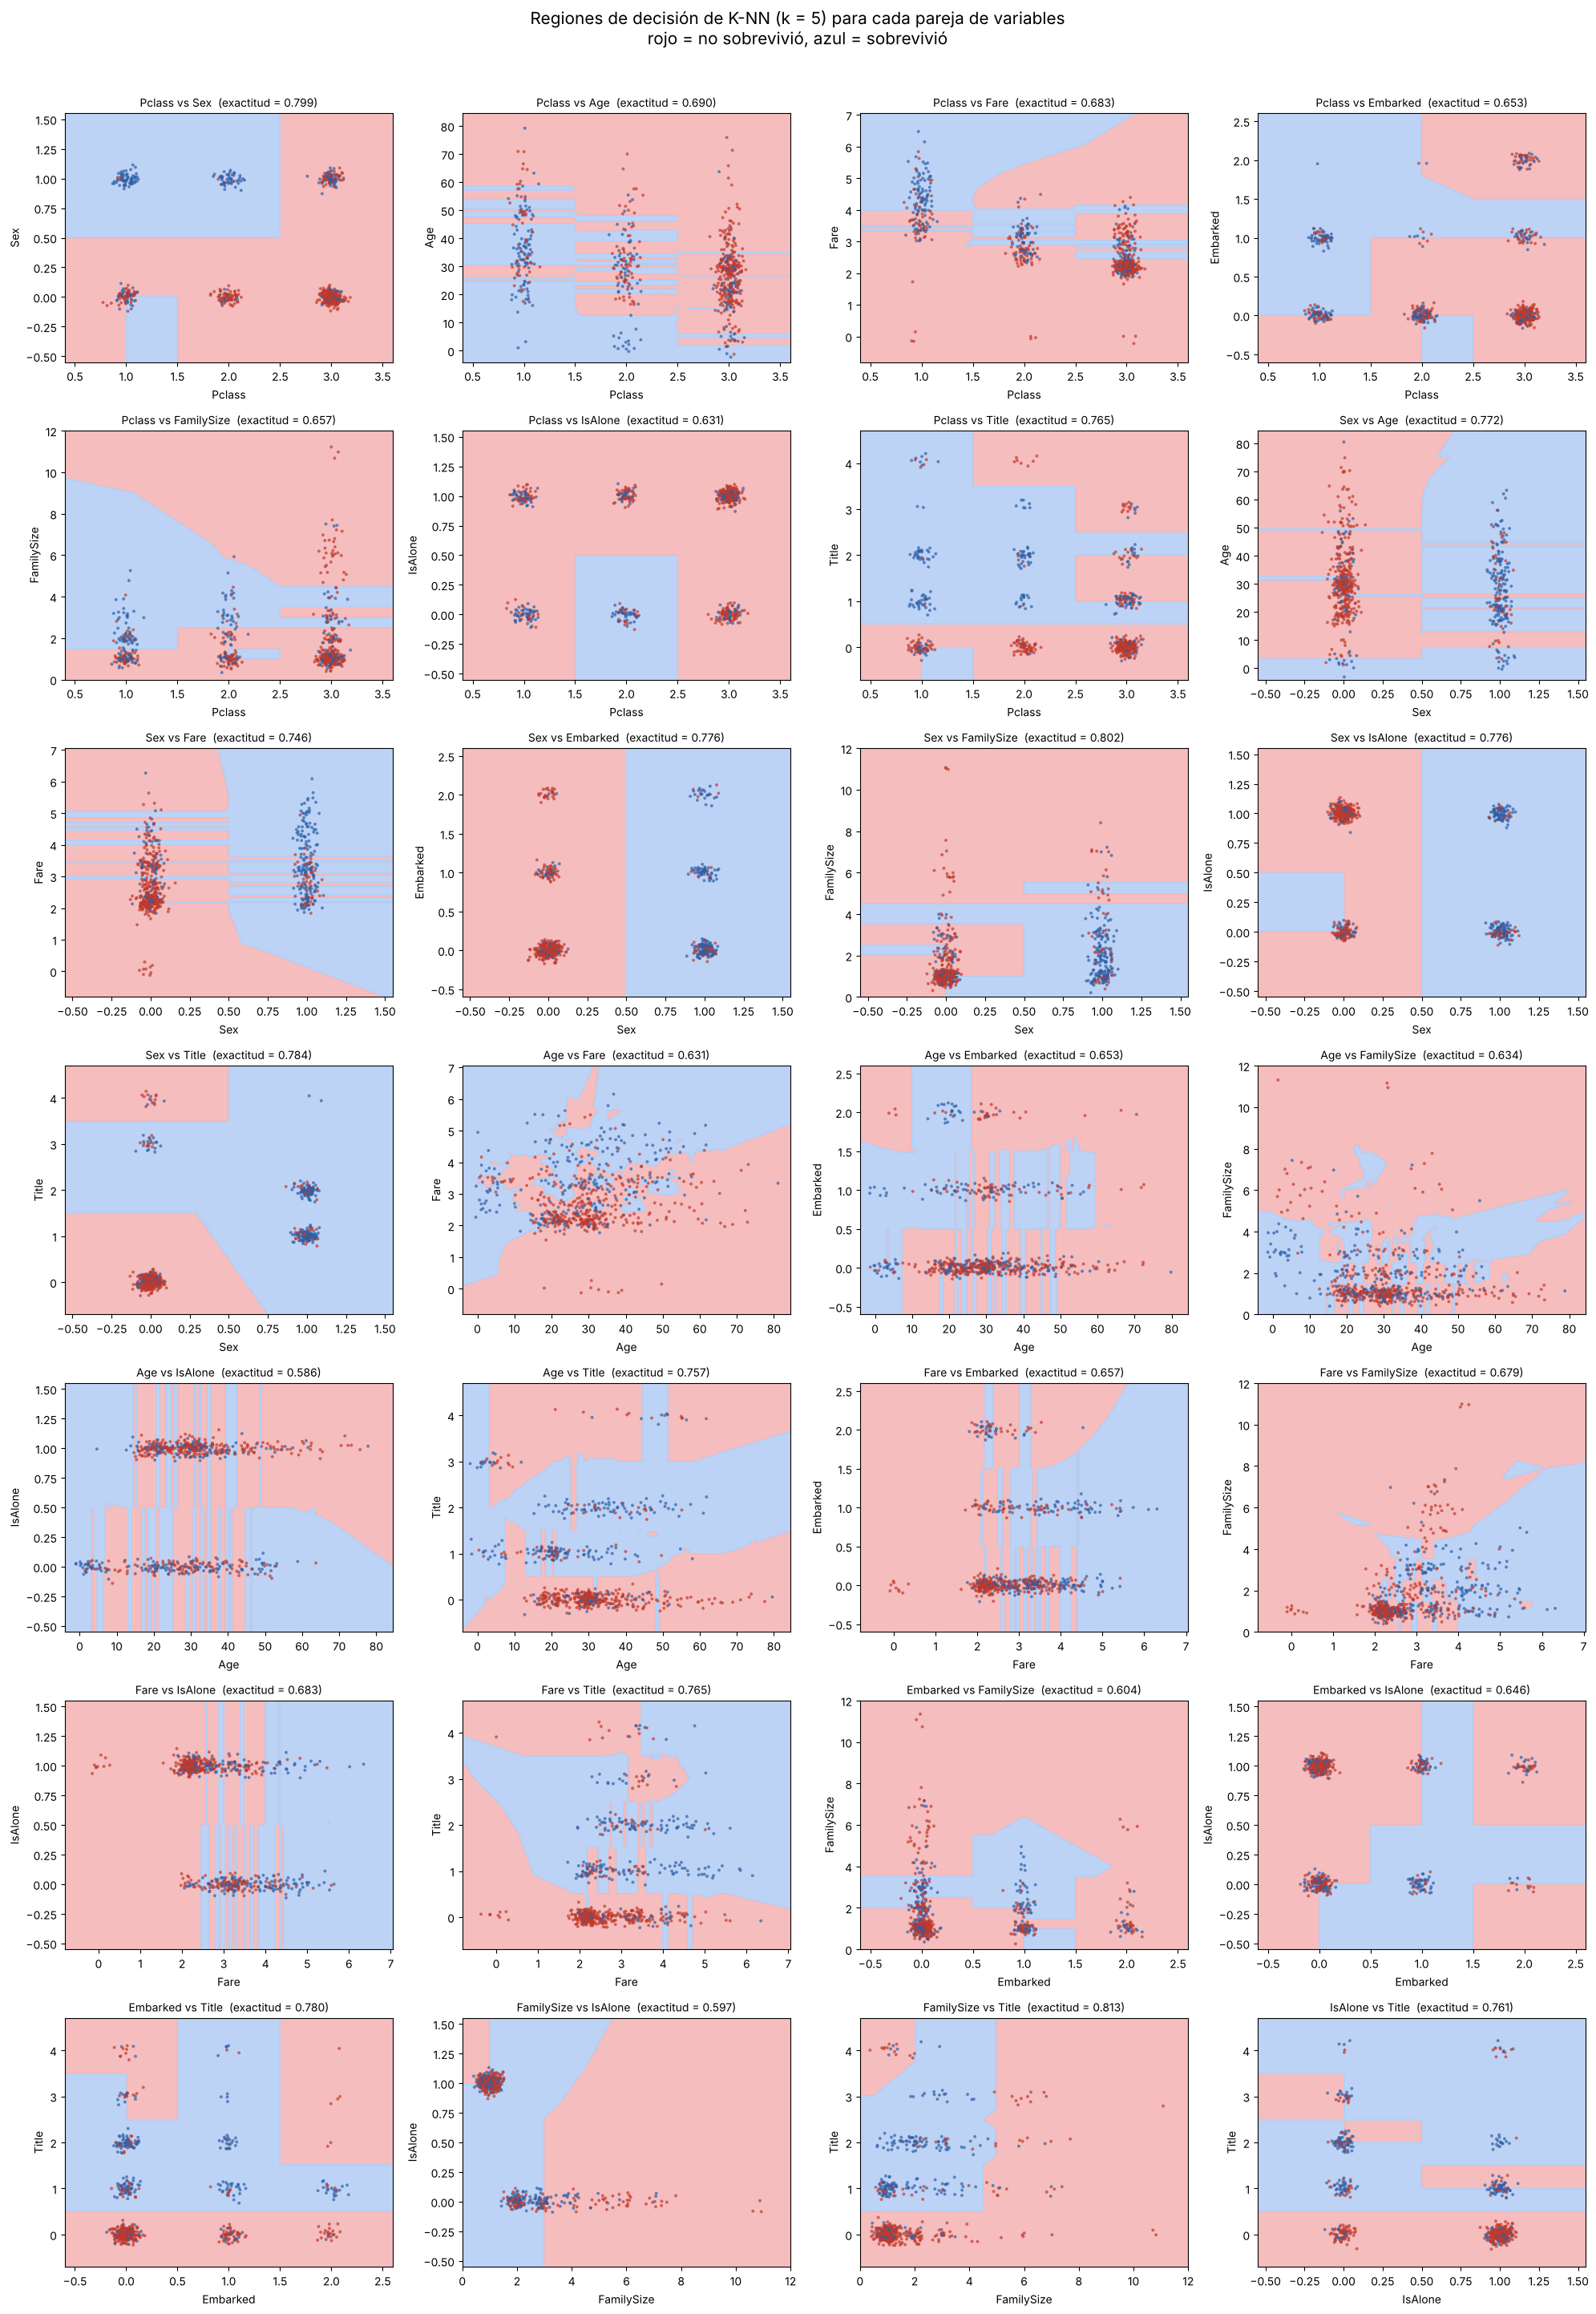

In [5]:
cmap_bg = ListedColormap(["#f4b6b6", "#b6cff4"])
cmap_pts = ListedColormap(["#c0392b", "#2c5fa8"])
rng = np.random.default_rng(0)

def plot_regions(ax, model, f1, f2, Xd, yd, h=200):
    x_min, x_max = Xd[f1].min(), Xd[f1].max()
    y_min, y_max = Xd[f2].min(), Xd[f2].max()
    pad_x = 0.05 * (x_max - x_min) + 0.5
    pad_y = 0.05 * (y_max - y_min) + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min - pad_x, x_max + pad_x, h),
                         np.linspace(y_min - pad_y, y_max + pad_y, h))
    grid = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.9)

    jx = rng.normal(0, 0.02 * (x_max - x_min + 1), len(Xd))
    jy = rng.normal(0, 0.02 * (y_max - y_min + 1), len(Xd))
    ax.scatter(Xd[f1] + jx, Xd[f2] + jy, c=yd, cmap=cmap_pts, s=8, edgecolors="none", alpha=0.7)
    ax.set_xlabel(f1)
    ax.set_ylabel(f2)

ncols = 4
nrows = int(np.ceil(len(pairs) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
acc_map = {(r["Variable 1"], r["Variable 2"]): r["Exactitud"] for r in results}

for ax, (f1, f2) in zip(axes.ravel(), pairs):
    plot_regions(ax, models[(f1, f2)], f1, f2, X_train, y_train)
    ax.set_title(f"{f1} vs {f2}  (exactitud = {acc_map[(f1, f2)]:.3f})", fontsize=10)

for ax in axes.ravel()[len(pairs):]:
    ax.axis("off")

fig.suptitle(f"Regiones de decisión de K-NN (k = {K}) para cada pareja de variables\n"
             "rojo = no sobrevivió, azul = sobrevivió", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 5. Mejores parejas

Top 5 parejas por exactitud en prueba:
Variable 1 Variable 2  Exactitud
FamilySize      Title      0.813
       Sex FamilySize      0.802
    Pclass        Sex      0.799
       Sex      Title      0.784
  Embarked      Title      0.780


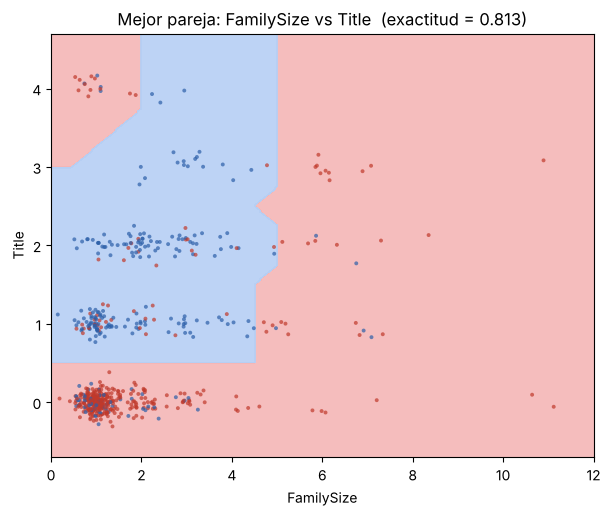

In [6]:
print("Top 5 parejas por exactitud en prueba:")
print(results_df.head(5).to_string(index=False))

best = tuple(results_df.loc[0, ["Variable 1", "Variable 2"]])
fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, models[best], best[0], best[1], X_train, y_train, h=300)
ax.set_title(f"Mejor pareja: {best[0]} vs {best[1]}  (exactitud = {results_df.loc[0, 'Exactitud']:.3f})")
plt.show()

## 6. Conclusiones

- Las parejas que incluyen **`Sex`** o **`Title`** suelen dar la mayor exactitud, porque el sexo (y el título, que lo resume junto con la edad) es la variable que más separa a quienes sobrevivieron.
- Con variables discretas (`Pclass`, `Sex`, `Embarked`, `IsAlone`) las regiones salen en **bloques rectangulares**, porque los pasajeros se agrupan en pocos valores.
- Con variables continuas (`Age`, `Fare`) las fronteras son más irregulares: K-NN se adapta localmente a los vecinos y puede producir islas pequeñas.
- Escalar las variables es necesario: sin `StandardScaler`, la variable con mayor rango (como `Age`) dominaría la distancia.